In [1]:
# --- repository root ---------------------------------------------------
# The notebooks live in notebooks/, the package in succd/, the data in data/.
# This cell finds the repository root (the folder holding pyproject.toml),
# makes it the working directory and puts it on sys.path, so that
# `from succd import ...` works without installing the package.
import os, sys
_d = os.path.abspath(os.getcwd())
while not os.path.isfile(os.path.join(_d, 'pyproject.toml')):
    if _d == os.path.dirname(_d):
        raise FileNotFoundError('repository root not found: expected a parent folder '
                                'holding pyproject.toml and succd/')
    _d = os.path.dirname(_d)
REPO = _d
os.environ['SUCCD_ROOT'] = REPO
os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)
from succd import paths            # data folders: paths.RESULTS, paths.VALUES, paths.SI ...
print('repository root:', os.path.basename(REPO), '(found and set as working directory)')


repository root: selected-uccd (found and set as working directory)


# s-UCCD — all calculations, one table, then the figures

Every molecule goes through the same functions; the loop collects the results into
`TABLE`; the figure cells are the ones of notebook 1, unchanged except that
they read `TABLE` instead of a CSV.

Needs the `succd` package (found automatically by the first cell) and the full
PySCF + Qiskit stack of `requirements.txt`.

## Setup

In [2]:
# qiskit-algorithms 0.4.0 has a circular import that fires on some installs
# when qiskit-nature first pulls it in; succd/__init__.py applies the
# workaround (see scripts/check_environment.py).
import os, sys, json, time, math, warnings, importlib
warnings.filterwarnings('ignore')

import succd
from succd import PySCFDriver_mod_vers
importlib.reload(PySCFDriver_mod_vers)     # pyscf_problem_extended reloads it too
CODE = os.path.dirname(os.path.abspath(succd.__file__))
print('package :', os.path.relpath(CODE, paths.ROOT), '| reload OK')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
from pyscf import gto, scf, cc, ci
from pyscf.fci import direct_spin1, cistring
from scipy.sparse.linalg import LinearOperator, eigsh
from math import comb

from succd import core, drv
from succd import selected_cc_pipeline as scp
K = core.K                        # Hartree -> kcal/mol


Ades Reigns
Ades Reigns
package : succd | reload OK


## Geometries

Angstrom, STO-6G. Second entry is the number of frozen core orbitals. Acetylene is `C2H2`
here and in `succd/geoms.py`.

In [3]:
H6 = """  H   -0.00000013033398     -0.00000027656978     -1.63585537349176
  H   -0.00000002026762     -0.00000001049860     -0.88216228307366
  H   0.00000005145092      0.00000026737096      2.12317470217342
  H   0.00000019741506      0.00000028652252      2.87682413358394
  H   0.00000001191796      0.00000000445340      5.88216389396856
  H   -0.00000011018233     -0.00000027127849      6.63585492683949"""

H8 = """  H   0.00000014047129      0.00000007179489     -2.49463655320066
  H   0.00000005471022      0.00000003978284     -1.74094036515667
  H   -0.00000000410940     -0.00000006874485      1.24863503981317
  H   -0.00000012507223     -0.00000010066620      2.00229939584808
  H   -0.00000019452856     -0.00000006736999      4.99770518795901
  H   -0.00000012436358      0.00000002198468      5.75136984133156
  H   0.00000006114635     -0.00000000235498      8.74093595148680
  H   0.00000019174591      0.00000010557361      9.49463150191870"""

N2 = """  N   0.00000000000000      0.00000000000000      0.03808486286764
  N   0.00000000000000      0.00000000000000      1.16191513713236"""

CO = """  O   -1.07180221708728      0.00000000000000      0.00000000000000
  C   0.07180221708728      0.00000000000000      0.00000000000000"""

CH2O = """  H   1.07578703937518     -0.14380969167056      1.05707279366277
  C   0.59552162304750      0.01521281882427      0.06858835087804
  H   1.27921938071923      0.20323734246116     -0.78595667392319
  O   -0.61132804314190     -0.01554046961487     -0.07040447061762"""

C2H2 = """  C   0.59610628651506      0.01277743826555      0.14122987213962
  C   -0.59608390436389     -0.01275984381194     -0.14117151138292
  H   1.63992701862499      0.03514052846642      0.38864357314535
  H   -1.63994940077616     -0.03505812292003     -0.38840193390205"""

GEOM = {'H6':   (H6,   0),
        'H8':   (H8,   0),
        'N2':   (N2,   2),
        'CO':   (CO,   2),
        'CH2O': (CH2O, 2),
        'C2H2': (C2H2, 2)}
BASIS = 'sto-6g'
ALL = ['H6', 'N2', 'CO', 'H8', 'CH2O', 'C2H2']       # cheapest first

core.SYSTEMS = GEOM                        # these geometries are authoritative
from succd import geoms
geoms.SYSTEMS.clear(); geoms.SYSTEMS.update(GEOM)

for k, (g, nf) in GEOM.items():
    print('%-5s frozen=%d  atoms=%d' % (k, nf, len(g.strip().splitlines())))

H6    frozen=0  atoms=6
H8    frozen=0  atoms=8
N2    frozen=2  atoms=2
CO    frozen=2  atoms=2
CH2O  frozen=2  atoms=4
C2H2  frozen=2  atoms=4


## Config

**`DO_VQE`** — one key per molecule. `True` locates the variational optimum p_m, `False`
leaves that entry blank and computes everything else. It is the only genuinely
unaffordable step: it needs thousands of circuit evaluations, and on the twenty-qubit
molecules one evaluation costs about a minute.

**`VQE_START`** — `'t'` starts the optimiser from the s-CCD amplitudes, `'c'` from the
s-CID coefficients. Starting from t_m is usually the cheaper route to the same optimum.

**`VQE_MAXIT`** — iteration ceiling, per molecule.

**`SWEEP_STEP`** — the operator-count spacing in Figure 4. This is why CH2O and C2H2 had
fewer points than the rest: they were run at 25 instead of 5. Each sweep point costs one
s-CID diagonalisation, one s-CCD solve and three circuit evaluations, so on twenty qubits
a single point is several minutes. Lower the number to get a denser curve and pay for it.

In [4]:
RUN   = ALL                           # all six systems; ['H6', 'N2'] for a quick run
TAG   = 'run1'
DELTA = 3e-4                          # selection threshold, Hartree

#                H6     N2     CO     H8     CH2O   C2H2
DO_VQE    = {'H6': True,  'N2': True,  'CO': True,
             'H8': True,  'CH2O': False, 'C2H2': False}
VQE_START = {m: 't' for m in ALL}     # 't' = s-CCD amplitudes, 'c' = s-CID coefficients
VQE_MAXIT = {m: 4000 for m in ALL}
SWEEP_STEP = {'H6': 5, 'N2': 5, 'CO': 5, 'H8': 5, 'CH2O': 25, 'C2H2': 25}
DO_SWEEP = True                       # Figure 4 only

core.DELTA = DELTA
BIG    = {'CH2O', 'C2H2'}             # 20 qubits, ~1 min per circuit evaluation
ROOT   = paths.ROOT
FIGDIR = os.path.join(ROOT, 'figures_%s' % TAG)
VALDIR = os.path.join(ROOT, 'values_%s' % TAG)
os.makedirs(FIGDIR, exist_ok=True); os.makedirs(VALDIR, exist_ok=True)

print('run   ', RUN)
print('VQE   ', {m: DO_VQE[m] for m in RUN}, 'start', {m: VQE_START[m] for m in RUN},
      'maxit', {m: VQE_MAXIT[m] for m in RUN})
print('sweep ', {m: SWEEP_STEP[m] for m in RUN}, '| delta', DELTA)

run    ['H6', 'N2', 'CO', 'H8', 'CH2O', 'C2H2']
VQE    {'H6': True, 'N2': True, 'CO': True, 'H8': True, 'CH2O': False, 'C2H2': False} start {'H6': 't', 'N2': 't', 'CO': 't', 'H8': 't', 'CH2O': 't', 'C2H2': 't'} maxit {'H6': 4000, 'N2': 4000, 'CO': 4000, 'H8': 4000, 'CH2O': 4000, 'C2H2': 4000}
sweep  {'H6': 5, 'N2': 5, 'CO': 5, 'H8': 5, 'CH2O': 25, 'C2H2': 25} | delta 0.0003


## The functions

In [5]:
def f_build(name):
    """Active space, doubles manifold with MP2 estimates, JW generators, tapered H."""
    C = core.build(name)
    return C


def f_select(C):
    """Doubles whose second-order estimate exceeds DELTA. Prunes C['mapped'] in place."""
    scores = np.sort(np.abs(C['dfr']['E2_i'].values))[::-1]
    N = core.nsel(C)
    gap = float(scores[N-1] - scores[N]) if N < len(scores) else float('nan')
    return N, scores, gap


def f_classical(C, N):
    """c_m, c'_m, t_m and the closed-form d_m = alpha_est * c_m of Eq. 5."""
    P = core.params(C, N, False)
    c0 = P['c0']
    a  = (2 - c0**2) / c0
    P['alpha_est'] = a
    P['dm'] = a * P['c']
    return P


def f_energies(C, N, P):
    """<H> of the circuit for each parameter set."""
    Ev = core.evaluator(C)
    return {k: float(Ev(P[v], N)) for k, v in
            (('c_m', 'c'), ('cp_m', 'cp'), ('d_m', 'dm'), ('t_m', 't'))}


def f_alpha(C, N, P, big=False):
    """Best single scalar along the c_m ray."""
    Ev = core.evaluator(C)
    if big:                       # grid + parabola: Brent is too many evaluations
        grid = [1.05, 1.10, 1.15, 1.20]
        E = [float(Ev(a * P['c'], N)) for a in grid]
        i = int(np.argmin(E)); sl = slice(max(0, i-1), i+2)
        q = np.polyfit(grid[sl], E[sl], 2)
        x = float(-q[1] / (2*q[0]))
        return x, float(np.polyval(q, x))
    r = minimize_scalar(lambda a: Ev(a * P['c'], N), bracket=(1.0, 1.15),
                        method='brent', options={'xtol': 1e-6})
    return float(r.x), float(r.fun)


def f_vqe(C, N, P, maxit=4000, start='c'):
    """Variational optimum p_m of the fixed ansatz."""
    Ev = core.evaluator(C)
    r = minimize(lambda p: Ev(p, N), P[start], method='L-BFGS-B',
                 options={'maxiter': maxit, 'ftol': 1e-13, 'gtol': 1e-9})
    return float(r.fun), int(r.nit), bool(r.success)


def f_quad(C, N):
    """N_Q and the exact energy of HF + doubles + the quadruples they generate."""
    HFa, HFb = int(C['HFdet'][0]), int(C['HFdet'][1])
    dd = [(int(d[0]), int(d[1])) for d in C['double_dets'][:N]]
    ops = [((HFa & ~a), (a & ~HFa), (HFb & ~b), (b & ~HFb)) for a, b in dd]

    def ap(op, D):
        ra, aa, rb, ab = op; Da, Db = D
        if (Da & ra) != ra or (Da & aa) or (Db & rb) != rb or (Db & ab):
            return None
        return ((Da & ~ra) | aa, (Db & ~rb) | ab)

    Q = set()
    for i in range(N):
        for j in range(i+1, N):
            R = ap(ops[i], dd[j])
            if R and ((HFa ^ R[0]).bit_count() + (HFb ^ R[1]).bit_count()) // 2 >= 4:
                Q.add(R)
    M, na, nb = C['M'], C['na'], C['nb']
    ns = cistring.num_strings(M, na)
    h2e = direct_spin1.absorb_h1e(C['h1'], C['eri'], M, (na, nb), .5)
    ad = np.unique([cistring.str2addr(M, na, x) * ns + cistring.str2addr(M, nb, y)
                    for x, y in [(HFa, HFb)] + dd + sorted(Q)])

    def mv(x):
        v = np.zeros(ns*ns); v[ad] = x
        return direct_spin1.contract_2e(h2e, v.reshape(ns, ns), M, (na, nb)).ravel()[ad]

    lam = eigsh(LinearOperator((len(ad),)*2, matvec=mv, dtype=float), k=1,
                which='SA', tol=1e-11, maxiter=60000)[0][0]
    return len(Q), float((lam + C['shift']) * K), int(ns*ns)


def f_refs(C, name):
    """Active-space FCI, and unselected CISD / CCSD."""
    M, na, nb = C['M'], C['na'], C['nb']
    lam, _ = direct_spin1.kernel(C['h1'], C['eri'], M, (na, nb), conv_tol=1e-13)
    xyz, nf = GEOM[name]
    mol = gto.M(atom=xyz, basis=BASIS, verbose=0)
    mf = scf.RHF(mol).run()
    return (float((lam + C['shift']) * K),
            float(ci.CISD(mf, frozen=nf).run().e_corr * K),
            float(cc.CCSD(mf, frozen=nf).run().e_corr * K))

In [6]:
from qiskit import transpile
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit_nature.second_q.circuit.library import HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper


def f_gates(C, N):
    """Transpiled cost of s-UCCD (N selected doubles) and of full UCCSD.

    Two traps: core.nsel prunes C['mapped'] IN PLACE, and the full pool is em_jw --
    the complete excitation list -- not the pre-screened doubles."""
    def circ(ops):
        hf = HartreeFock(C['M'], C['npart'], JordanWignerMapper())
        q = QuantumCircuit(hf.num_qubits); q.compose(hf, inplace=True)
        for o in ops:
            q.append(PauliEvolutionGate(o, time=0.1), range(hf.num_qubits))
        return q

    def cnt(q):
        t = transpile(q, basis_gates=['cx', 'rz', 'sx', 'x'],
                      optimization_level=1, seed_transpiler=7)
        d = dict(t.count_ops())
        return dict(nq=t.num_qubits, depth=t.depth(), cx=d.get('cx', 0),
                    total=sum(d.values()))

    em, mp = C['em_jw'], C['mapped']
    return cnt(circ([em[mp[k]] for k in range(N)])), \
           cnt(circ([o for o in em if o is not None]))


def f_sqd(C, N, P):
    """Sampled diagonalisation at 1e8 measurements, for all three parameter sources,
    in both the doubles-only and the singles-inclusive subspace.

    Returns {('D'|'SD', 'c_m'|'d_m'|'t_m'): {'E':..., 'N':...}} and the number of
    PT2-selected singles."""
    out = {}
    for tag, vec in (('c_m', P['c']), ('d_m', P['dm']), ('t_m', P['t'])):
        out[('D', tag)] = drv.sqd(core.state(C, vec), C)['1e+08']
    sets, take, info = drv._sd_sets(C, N)
    a = P['alpha_est']
    for tag, vec in (('c_m', sets['c']), ('d_m', sets['c'] * a), ('t_m', sets['t'])):
        out[('SD', tag)] = drv.sqd(core.state(C, vec, take), C)['1e+08']
    return out, int(info['ns'])


def f_sweep(C, Nmax, step):
    """dE' = E_sCCD - E_sUCCD(x_m) against N. Everything is rebuilt at each N."""
    Ev = core.evaluator(C)
    grid = list(range(step, Nmax+1, step))
    if grid[-1] != Nmax:
        grid.append(Nmax)
    out = []
    for N in grid:
        dbl = [tuple(map(int, x)) for x in C['dbl'][:N]]
        sg = np.sign(C['dfr']['t_mp'].values[:N]).astype(float)
        Ecid, vec = scp.ci_corr([C['HFdet']] + C['double_dets'][:N], C['h1'], C['eri'])
        c0 = abs(vec[0]); cm = np.abs(vec[1:1+N]); a = (2 - c0**2)/c0
        Ecc, _, t2 = scp.SelectedCCSD(C['fock'], C['g'], C['nocc'], C['nvirt'],
                                      selected_singles=[], selected_doubles=dbl,
                                      so_labels=C['lbl']).kernel()
        tm = np.abs(np.array([t2[i, j, x, y] for (i, j, x, y) in dbl]))
        E = Ecc * K
        out.append(dict(N=N, c0=float(c0),
                        dE_cm=E - float(Ev(cm*sg, N)),
                        dE_dm=E - float(Ev(a*cm*sg, N)),
                        dE_tm=E - float(Ev(tm*sg, N))))
    return out


def f_noise(C, N, P, fidelity=0.9977):
    """Eq. 11: how many two-qubit gates the sampled route tolerates."""
    psi = core.state(C, P['dm']); w = np.abs(psi)**2; w /= w.sum()
    M, na, nb = C['M'], C['na'], C['nb']
    ns = cistring.num_strings(M, na); msk = (1 << M) - 1
    h2e = direct_spin1.absorb_h1e(C['h1'], C['eri'], M, (na, nb), .5)
    idx = [i for i in np.where(w > 1e-14)[0]
           if bin(int(i) & msk).count('1') == na
           and bin((int(i) >> M) & msk).count('1') == nb]
    order = sorted(idx, key=lambda i: -w[i])

    def en(sub):
        a = np.unique([cistring.str2addr(M, na, int(i) & msk) * ns +
                       cistring.str2addr(M, nb, (int(i) >> M) & msk) for i in sub])
        def mv(x):
            v = np.zeros(ns*ns); v[a] = x
            return direct_spin1.contract_2e(h2e, v.reshape(ns, ns),
                                            M, (na, nb)).ravel()[a]
        l = eigsh(LinearOperator((len(a),)*2, matvec=mv, dtype=float), k=1,
                  which='SA', tol=1e-10, maxiter=40000)[0][0]
        return float((l + C['shift']) * K)

    tgt = 0.95 * en(order); lo, hi = 1, len(order)
    while lo < hi:
        mid = (lo + hi) // 2
        if en(order[:mid]) <= tgt: hi = mid
        else: lo = mid + 1
    wmin = float(w[order[lo-1]]); D = comb(M, na) * comb(M, nb)
    p = 1.0 / (1.0 + D * wmin)
    return dict(dets_95=lo, populated=len(order), D=D, w_min=wmin,
                D_wmin=D*wmin, p_required=p,
                N_CX=int(math.floor(math.log(p) / math.log(fidelity))))

## One molecule, start to finish

In [7]:
def run_system(name, verbose=True):
    big     = name in BIG
    do_vqe  = DO_VQE.get(name, True)
    start   = VQE_START.get(name, 't')
    maxit   = VQE_MAXIT.get(name, 4000)
    step    = SWEEP_STEP.get(name, 5)
    say = (lambda *a: print(*a, flush=True)) if verbose else (lambda *a: None)

    t0 = time.time()
    say('--- %s ---' % name)
    C = f_build(name)
    N, scores, gap = f_select(C)
    say('  N = %d of %d doubles,  gap at cut %.2e,  qubits %d'
        % (N, len(scores), gap, 2 * C['M']))

    P = f_classical(C, N)
    E = f_energies(C, N, P)
    say('  c0 %.5f   alpha_est %.4f' % (P['c0'], P['alpha_est']))
    say('  s-UCCD  c_m %+9.4f   d_m %+9.4f   t_m %+9.4f'
        % (E['c_m'], E['d_m'], E['t_m']))
    say('  s-CID   %+9.4f   s-CCD %+9.4f' % (P['E_sCID'], P['E_sCCD']))

    astar, Ea = f_alpha(C, N, P, big=big)
    if do_vqe:
        Epm, nit, conv = f_vqe(C, N, P, maxit=maxit, start=start)
        say('  p_m %+9.4f   from %s_m, %d iterations, converged=%s'
            % (Epm, start, nit, conv))
    else:
        Epm, nit, conv = float('nan'), 0, False
        say('  p_m skipped (DO_VQE[%r] = False)' % name)

    NQ, EDQ, fcidim = f_quad(C, N)
    FCI, CISD, CCSD = f_refs(C, name)
    gsel, gfull = f_gates(C, N)
    sq, n_singles = f_sqd(C, N, P)
    swp = f_sweep(C, N, step) if DO_SWEEP else []
    noi = f_noise(C, N, P)

    say('  FCI %+9.4f   CISD %+9.4f   CCSD %+9.4f' % (FCI, CISD, CCSD))
    say('  N_Q %d   E_CI(D+Q) %+9.4f   CX %d   %.0f s'
        % (NQ, EDQ, gsel['cx'], time.time() - t0))

    r = dict(molecule=name, N_D=N, n_total_doubles=len(scores), N_S_pt2=n_singles,
             N_FCI=fcidim, qubits=2 * C['M'], depth=gsel['depth'], gap_at_cut=gap,
             c0=P['c0'], alpha_est=P['alpha_est'], alpha_star=astar, E_alpha=Ea,
             E_cm=E['c_m'], E_cpm=E['cp_m'], E_dm=E['d_m'], E_tm=E['t_m'],
             E_sCID=P['E_sCID'], E_sCCD=P['E_sCCD'], CISD=CISD, CCSD=CCSD, FCI=FCI,
             E_Enh=CISD + (E['d_m'] - P['E_sCID']),
             E_pm=Epm, vqe_converged=conv, vqe_nit=nit, vqe_start=start,
             NQ=NQ, E_DQ=EDQ, N_CX=gsel['cx'], N_gates=gsel['total'],
             N_CX_UCCSD=gfull['cx'], N_gates_UCCSD=gfull['total'],
             depth_UCCSD=gfull['depth'], sweep=swp, noise=noi)
    for (sub, src), v in sq.items():
        r['SQD_%s_%s' % (sub, src)] = v['E']
        r['nSQD_%s_%s' % (sub, src)] = v['N']
    return r

## The loop

In [8]:
RES = {}
T0 = time.time()
for name in RUN:
    try:
        RES[name] = run_system(name)
    except Exception as e:
        print('!! %s failed: %s' % (name, e))
print('\ntotal %.0f s' % (time.time() - T0))

# Results accumulate across sessions, but only records carrying the current set of
# keys are kept: an older file written before a column existed would otherwise be
# merged back in and break the table with a KeyError.
REQUIRED = {'E_cm', 'E_dm', 'E_tm', 'E_pm', 'E_sCID', 'E_sCCD', 'CISD', 'CCSD',
            'FCI', 'E_Enh', 'E_DQ', 'N_D', 'N_S_pt2', 'N_FCI', 'N_CX', 'N_gates',
            'SQD_D_c_m', 'SQD_D_d_m', 'SQD_D_t_m',
            'SQD_SD_c_m', 'SQD_SD_d_m', 'SQD_SD_t_m'}

store = os.path.join(VALDIR, 'results.json')
prev = json.load(open(store)) if os.path.exists(store) else {}
stale = [m for m, v in prev.items() if not REQUIRED.issubset(v) and m not in RES]
for m in stale:
    prev.pop(m)
if stale:
    print('dropped stale records (missing %s): %s'
          % (', '.join(sorted(REQUIRED - set(json.load(open(store))[stale[0]]))), stale))
    print('re-run those molecules to bring them back')
prev.update(RES)
json.dump(prev, open(store, 'w'), indent=1)
RES = prev
print('molecules on file:', list(RES))

--- H6 ---


Ades Reigns


['1A', '2A', '3A', '4A', '5A', '6A', '1B', '2B', '3B', '4B', '5B', '6B']




 Other important parts for the problem created now.
        
        A. Number of spin orbitals is: 12
        B. The number of JW configuration is: 2^12 =  4096
        C. Hence the JW matrix is a: 12 x 12
        D. Occupied orbitals: 3
        E. Unoccupied orbitals: 3
         



Time for JW Mapping:  4.339896202087402 



Time for Tapering Symmerties:  2.091353416442871 



Elimination of Useless column saved into: df2
Elimination of Useless column Active in df1


... (71 outputs left out)

  p_m skipped (DO_VQE['C2H2'] = False)


  FCI -112.8240   CISD -102.1049   CCSD -111.0629


  N_Q 785   E_CI(D+Q) -103.6976   CX 10660   800 s



total 2625 s
molecules on file: ['H6', 'N2', 'CO', 'H8', 'CH2O', 'C2H2']


## The table

Rows are molecules, columns every energy and every count. Energies are correlation
energies in kcal/mol from Hartree-Fock. `s-UCCD(p_m)` is blank where `DO_VQE` was
`False`.

In [9]:
ORDER = [m for m in ['C2H2', 'N2', 'CH2O', 'CO', 'H8', 'H6'] if m in RES]

COLS = [('s-UCCD(c_m)', 'E_cm'), ('s-UCCD(d_m)', 'E_dm'), ('s-UCCD(t_m)', 'E_tm'),
        ('s-UCCD(p_m)', 'E_pm'), ('s-CID', 'E_sCID'), ('s-CCD', 'E_sCCD'),
        ('CISD', 'CISD'), ('Enhanced CISD', 'E_Enh'), ('CCSD', 'CCSD'),
        ('E_CI(D+Q)', 'E_DQ'),
        ('SQD-D(c_m)', 'SQD_D_c_m'), ('SQD-D(d_m)', 'SQD_D_d_m'),
        ('SQD-D(t_m)', 'SQD_D_t_m'), ('SQD-SD(c_m)', 'SQD_SD_c_m'),
        ('SQD-SD(d_m)', 'SQD_SD_d_m'), ('SQD-SD(t_m)', 'SQD_SD_t_m'),
        ('FCI', 'FCI'),
        ('Num D conf', 'N_D'), ('Num Pt2 S conf', 'N_S_pt2'),
        ('Num FCI conf', 'N_FCI'), ('Num CX', 'N_CX'), ('Num all gates', 'N_gates')]

missing = {m: sorted({k for _, k in COLS} - set(RES[m])) for m in ORDER}
missing = {m: v for m, v in missing.items() if v}
if missing:
    print('incomplete records, columns will show NaN:', missing)
TABLE = pd.DataFrame({n: [RES[m].get(k, float('nan')) for m in ORDER]
                      for n, k in COLS}, index=ORDER)
TABLE.index.name = 'molecule'
TABLE.to_csv(os.path.join(VALDIR, '%s_table.csv' % TAG))

nfmt = {c: '{:.4f}'.format for c, _ in COLS[:17]}
nfmt.update({c: '{:.0f}'.format for c, _ in COLS[17:]})
with pd.option_context('display.width', 300, 'display.max_columns', 60):
    print('delta = %g Hartree    energies in kcal/mol from Hartree-Fock\n' % DELTA)
    print(TABLE.to_string(formatters=nfmt))
TABLE

delta = 0.0003 Hartree    energies in kcal/mol from Hartree-Fock

         s-UCCD(c_m) s-UCCD(d_m) s-UCCD(t_m) s-UCCD(p_m)    s-CID     s-CCD      CISD Enhanced CISD      CCSD E_CI(D+Q) SQD-D(c_m) SQD-D(d_m) SQD-D(t_m) SQD-SD(c_m) SQD-SD(d_m) SQD-SD(t_m)       FCI Num D conf Num Pt2 S conf Num FCI conf Num CX Num all gates
molecule                                                                                                                                                                                                                                                          
C2H2       -101.8758   -103.5460   -103.5834         NaN -94.9059 -102.4840 -102.1049     -110.7450 -111.0629 -103.6976  -104.7338  -104.7575  -104.7555   -104.8680   -105.0640   -105.0767 -112.8240         71              8        63504  10660         15064
N2          -99.6525   -100.8869   -100.8925   -100.9638 -93.7532  -99.6214  -95.5056     -102.6394 -101.6133 -101.1797  -101.5143  -101.6457  -101.6456   -1

,s-UCCD(c_m),s-UCCD(d_m),s-UCCD(t_m),s-UCCD(p_m),s-CID,s-CCD,CISD,Enhanced CISD,CCSD,E_CI(D+Q),...,SQD-D(t_m),SQD-SD(c_m),SQD-SD(d_m),SQD-SD(t_m),FCI,Num D conf,Num Pt2 S conf,Num FCI conf,Num CX,Num all gates
molecule,,,,,,,,,,,,,,,,,,,,,
C2H2,-101.875807,-103.545979,-103.583379,NaN,-94.905856,-102.483993,-102.104892,-110.745016,-111.062924,-103.697571,...,-104.755520,-104.868037,-105.063955,-105.076747,-112.824006,71,8,63504,10660,15064
N2,-99.652476,-100.886924,-100.892466,-100.963795,-93.753152,-99.621411,-95.505580,-102.639353,-101.613252,-101.179699,...,-101.645643,-101.894997,-102.026984,-102.027407,-104.407689,39,2,3136,4652,7034
CH2O,-82.322159,-82.813452,-82.863613,NaN,-78.801912,-82.509371,-86.322873,-90.334412,-90.662064,-83.055024,...,-83.820069,-85.519757,-85.734053,-85.783813,-92.373413,65,18,44100,8940,12913
CO,-79.185267,-79.729327,-79.733730,-79.746169,-75.501828,-79.232709,-81.136818,-85.364317,-84.034437,-79.806464,...,-80.127731,-86.747814,-86.784137,-86.864742,-89.507005,49,10,3136,5664,8639
H8,-43.573975,-43.676984,-43.680365,-43.682475,-42.336383,-43.679862,-51.251122,-52.591723,-53.224064,-43.667295,...,-43.682377,-43.682540,-43.682658,-43.682658,-53.224798,64,10,4900,8448,12439
H6,-38.571260,-38.624613,-38.631171,-38.633414,-37.721563,-38.648237,-38.900471,-39.803522,-39.910844,-38.672918,...,-39.894669,-39.894993,-39.894993,-39.894993,-39.911269,35,8,400,3696,5843


## Feeding the figures

The figure cells below are the ones from `04_figures_r15B.ipynb`, unchanged. They expect
the CSV layouts, so those layouts are rebuilt here from `TABLE` — one frame per figure.
Nothing is read from disk.

In [10]:
def _f(m, k):
    return float(RES[m][k])

FRAMES = {}

FRAMES['fig3_gates'] = pd.DataFrame(
    [dict(molecule=m, ansatz=a, n_qubits=RES[m]['qubits'],
          cx_gates=RES[m]['N_CX' + s], total_gates=RES[m]['N_gates' + s],
          depth=RES[m]['depth' + d])
     for m in ORDER
     for a, s, d in (('s-UCCD', '', ''), ('UCCSD', '_UCCSD', '_UCCSD'))])

FRAMES['fig4_sweep'] = pd.DataFrame(
    [dict(molecule=m, N=r['N'], dE_cm_kcalmol=r['dE_cm'],
          dE_dm_kcalmol=r['dE_dm'], dE_tm_kcalmol=r['dE_tm'], c0=r['c0'])
     for m in ORDER for r in RES[m]['sweep']])

FRAMES['fig5_residual'] = pd.DataFrame(
    [dict(molecule=m, source=s,
          residual_kcalmol=_f(m, k) - _f(m, 'E_pm'),
          pm_estimated=not RES[m]['vqe_converged'])
     for m in ORDER for s, k in (('c_m', 'E_cm'), ('d_m', 'E_dm'), ('t_m', 'E_tm'))])

FRAMES['fig6_quadruples'] = pd.DataFrame(
    [dict(molecule=m, quantity=q, energy_kcalmol=abs(_f(m, k) - _f(m, 'E_sCID')))
     for m in ORDER
     for q, k in (('|E_sUCCD(t_m) - E_sCID|', 'E_tm'),
                  ('|E_sUCCD(d_m) - E_sCID|', 'E_dm'),
                  ('|E_sCI(D+Q) - E_sCID|',   'E_DQ'))])

FRAMES['figA1_enhanced_cisd'] = pd.DataFrame(
    [dict(molecule=m, method=meth, dev_from_FCI_kcalmol=_f(m, k) - _f(m, 'FCI'))
     for m in ORDER
     for meth, k in (('CISD', 'CISD'), ('Enh(d_m)', 'E_Enh'), ('CCSD', 'CCSD'))])

FRAMES['figA2_sqd'] = pd.DataFrame(
    [dict(molecule=m, parameters=p, subspace=sub,
          abs_dev_from_FCI_kcalmol=abs(_f(m, 'SQD_%s_%s_m' % (tag, p)) - _f(m, 'FCI')),
          n_determinants=RES[m]['nSQD_%s_%s_m' % (tag, p)])
     for m in ORDER for p in ('c', 'd', 't')
     for sub, tag in (('SQD-D', 'D'), ('SQD-SD', 'SD'))])

FRAMES['figA3_determinants'] = pd.DataFrame(
    [dict(molecule=m, series=ser, count=cnt)
     for m in ORDER
     for ser, cnt in (('FCI space', RES[m]['N_FCI']),
                      ('SQD-D',  RES[m]['nSQD_D_d_m']),
                      ('SQD-SD', RES[m]['nSQD_SD_d_m']))])

for k, v in FRAMES.items():
    v.to_csv(os.path.join(VALDIR, '%s_%s.csv' % (TAG, k)), index=False)
    print('%-24s %3d rows' % (k, len(v)))

PRETTY = {'H6': r'$\mathrm{H_6}$', 'H8': r'$\mathrm{H_8}$', 'N2': r'$\mathrm{N_2}$',
          'CO': r'$\mathrm{CO}$', 'CH2O': r'$\mathrm{CH_2O}$',
          'C2H2': r'$\mathrm{C_2H_2}$'}
order = ORDER                      # the figure cells use this name

fig3_gates                12 rows
fig4_sweep                44 rows
fig5_residual             18 rows
fig6_quadruples           18 rows
figA1_enhanced_cisd       18 rows
figA2_sqd                 36 rows
figA3_determinants        18 rows


## Figures

Cells copied from `04_figures_r15B.ipynb`. The only edits: the data source is `FRAMES`
rather than a CSV, `order` follows the molecules actually present, and the files are saved
into `figures_<TAG>/` with the tag prefixed.

### Figure 3 — circuit cost

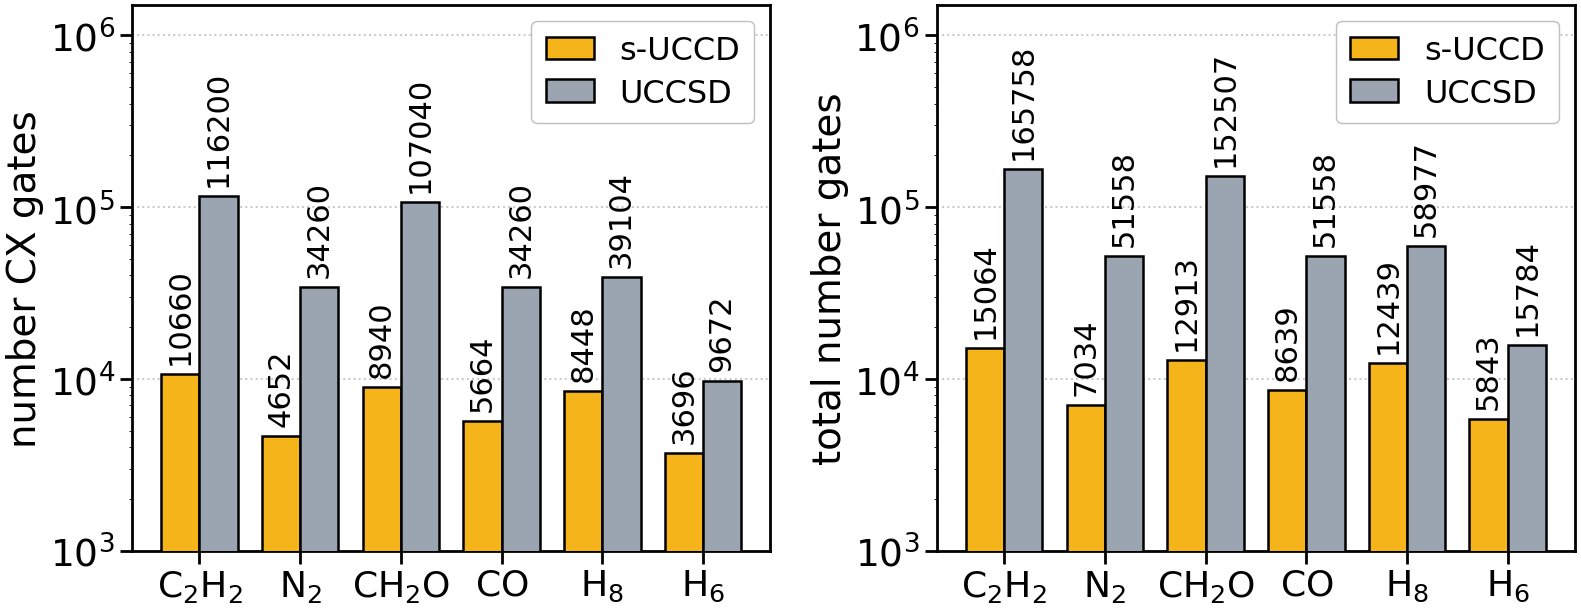

In [11]:
# ===================================================================
# FIGURE 3 — circuit cost.  Self-contained: run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 27, 26, 28, 23, 22
fig_w, fig_h, dpi = 16.5, 6.8, 600
bar_w          = 0.38          # width of one bar
y_bottom, y_top = 1e3, 1.5e6   # raise y_top if numerals hit the frame
colour_sUCCD   = "#f4b41a"
colour_UCCSD   = "#9aa5b1"
order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = FRAMES["fig3_gates"]
s  = df[df.ansatz == "s-UCCD"].set_index("molecule")
u  = df[df.ansatz == "UCCSD"].set_index("molecule")

cx_sUCCD    = [s.loc[m, "cx_gates"]    for m in order]
cx_UCCSD    = [u.loc[m, "cx_gates"]    for m in order]
total_sUCCD = [s.loc[m, "total_gates"] for m in order]
total_UCCSD = [u.loc[m, "total_gates"] for m in order]

x = np.arange(len(order))

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(fig_w, fig_h))

# ---- PLOT: LEFT PANEL, CX gates -----------------------------------
ax_left.set_yscale("log")
ax_left.set_ylim(y_bottom, y_top)

ax_left.bar(x - bar_w / 2, cx_sUCCD, bar_w, color=colour_sUCCD,
            edgecolor="black", linewidth=1.8, label="s-UCCD", zorder=3)
ax_left.bar(x + bar_w / 2, cx_UCCSD, bar_w, color=colour_UCCSD,
            edgecolor="black", linewidth=1.8, label="UCCSD", zorder=3)

for xi, v in zip(x - bar_w / 2, cx_sUCCD):          # numbers above the bars
    ax_left.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                 va="bottom", fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w / 2, cx_UCCSD):
    ax_left.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                 va="bottom", fontsize=fs_annot, clip_on=False)

ax_left.set_ylabel("number CX gates", fontsize=fs_label)
ax_left.set_xticks(x)
ax_left.set_xticklabels(labels, fontsize=fs_mol)
ax_left.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax_left.yaxis.set_minor_formatter(NullFormatter())
ax_left.grid(True, axis="y", zorder=0)
ax_left.set_axisbelow(True)
ax_left.legend(loc="upper right", fontsize=fs_legend)

# ---- PLOT: RIGHT PANEL, total gates -------------------------------
ax_right.set_yscale("log")
ax_right.set_ylim(y_bottom, y_top)

ax_right.bar(x - bar_w / 2, total_sUCCD, bar_w, color=colour_sUCCD,
             edgecolor="black", linewidth=1.8, label="s-UCCD", zorder=3)
ax_right.bar(x + bar_w / 2, total_UCCSD, bar_w, color=colour_UCCSD,
             edgecolor="black", linewidth=1.8, label="UCCSD", zorder=3)

for xi, v in zip(x - bar_w / 2, total_sUCCD):
    ax_right.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                  va="bottom", fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w / 2, total_UCCSD):
    ax_right.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center",
                  va="bottom", fontsize=fs_annot, clip_on=False)

ax_right.set_ylabel("total number gates", fontsize=fs_label)
ax_right.set_xticks(x)
ax_right.set_xticklabels(labels, fontsize=fs_mol)
ax_right.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax_right.yaxis.set_minor_formatter(NullFormatter())
ax_right.grid(True, axis="y", zorder=0)
ax_right.set_axisbelow(True)
ax_right.legend(loc="upper right", fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"{TAG}_fig3_circuit_cost.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/fig3_circuit_cost.pdf")
plt.show()

### Figure 4 — E(s-CCD) − E(s-UCCD)

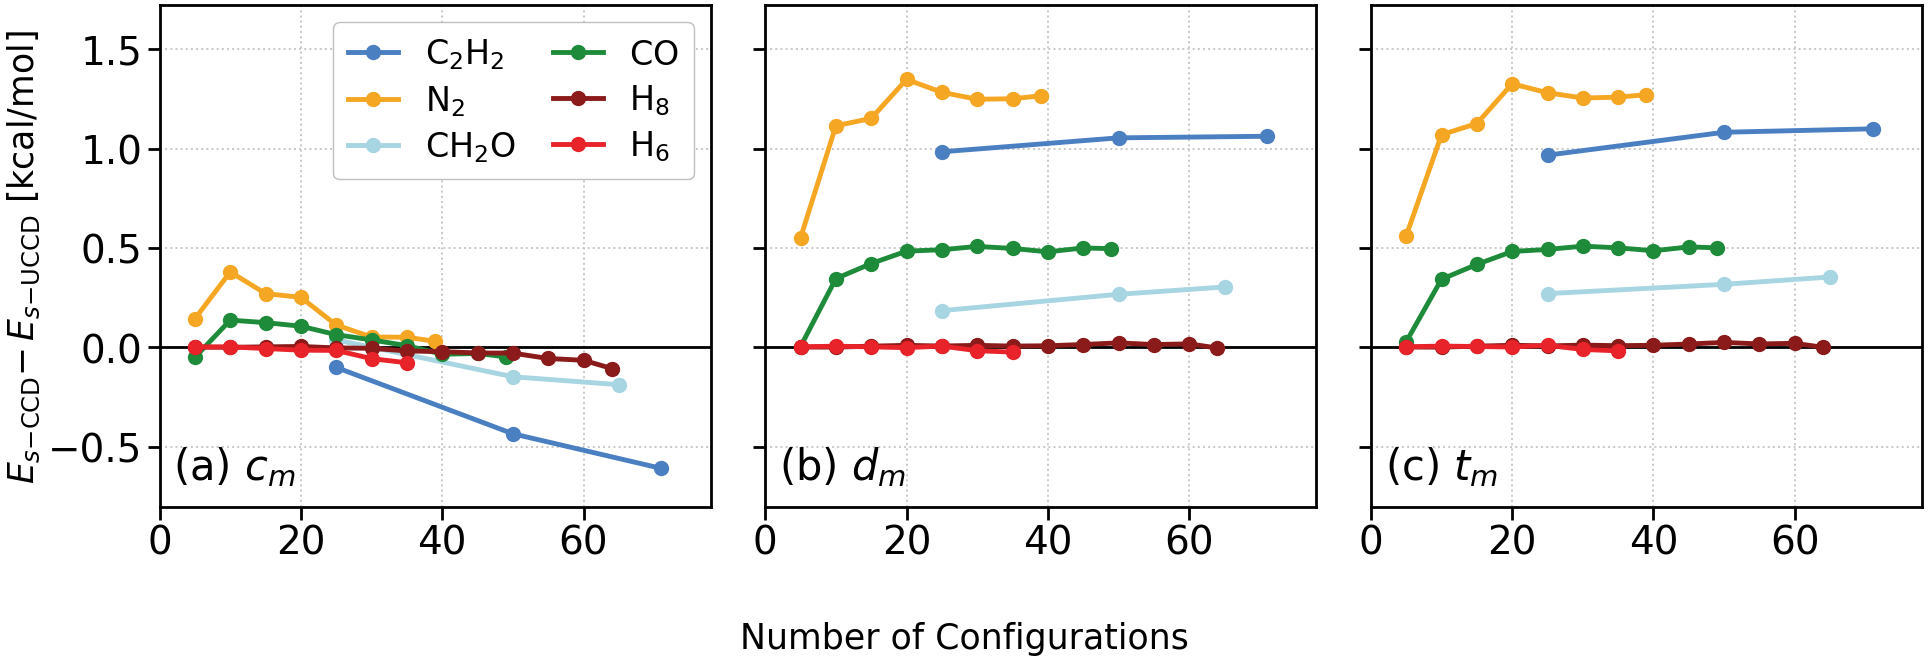

In [12]:
# ===================================================================
# FIGURE 4 — E(s-CCD) - E(s-UCCD).  Self-contained: run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_tag = 30, 32, 32, 27, 30
fig_w, fig_h, dpi = 20, 7, 600

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 24, 23


y_bottom, y_top   = -0.80, 1.72      # shared by all three panels
x_left, x_right   = 0, 78
marker_size, line_width = 10, 3.5
order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]
colours = ["#4a7fc1", "#f5a623", "#a8d5e2", "#1e8b3a", "#8b1a1a", "#e8232a"]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = FRAMES["fig4_sweep"]

fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(fig_w, fig_h),
                                       sharey=True)

# ---- PLOT: PANEL (a), raw coefficients c_m ------------------------
ax_a.axhline(0.0, color="black", linewidth=2.0, zorder=2)
for m, lab, col in zip(order, labels, colours):
    d = df[df.molecule == m].sort_values("N")
    ax_a.plot(d["N"], d["dE_cm_kcalmol"], marker="o", markersize=marker_size,
              linewidth=line_width, color=col, label=lab, zorder=3)
ax_a.set_xlim(x_left, x_right)
ax_a.set_ylim(y_bottom, y_top)
ax_a.grid(True, zorder=0)
ax_a.set_axisbelow(True)
ax_a.text(0.025, 0.035, r"(a) $c_m$", transform=ax_a.transAxes,
          fontsize=fs_tag, ha="left", va="bottom")
ax_a.set_ylabel(r"$E_{s\mathrm{-CCD}}$"  r"$-\,E_{s\mathrm{-UCCD}}$ [kcal/mol]" ,
                fontsize=fs_label)
ax_a.legend(loc="upper right", ncol=2, fontsize=fs_legend)

# ---- PLOT: PANEL (b), rescaled coefficients d_m -------------------
ax_b.axhline(0.0, color="black", linewidth=2.0, zorder=2)
for m, lab, col in zip(order, labels, colours):
    d = df[df.molecule == m].sort_values("N")
    ax_b.plot(d["N"], d["dE_dm_kcalmol"], marker="o", markersize=marker_size,
              linewidth=line_width, color=col, label=lab, zorder=3)
    #print('d["N"]', d["N"])
    
ax_b.set_xlim(x_left, x_right)
ax_b.set_ylim(y_bottom, y_top)
ax_b.grid(True, zorder=0)
ax_b.set_axisbelow(True)
ax_b.text(0.025, 0.035, r"(b) $d_m$", transform=ax_b.transAxes,
          fontsize=fs_tag, ha="left", va="bottom")

# ---- PLOT: PANEL (c), s-CCD amplitudes t_m ------------------------
ax_c.axhline(0.0, color="black", linewidth=2.0, zorder=2)
for m, lab, col in zip(order, labels, colours):
    d = df[df.molecule == m].sort_values("N")
    ax_c.plot(d["N"], d["dE_tm_kcalmol"], marker="o", markersize=marker_size,
              linewidth=line_width, color=col, label=lab, zorder=3)
ax_c.set_xlim(x_left, x_right)
ax_c.set_ylim(y_bottom, y_top)
ax_c.grid(True, zorder=0)
ax_c.set_axisbelow(True)
ax_c.text(0.025, 0.035, r"(c) $t_m$", transform=ax_c.transAxes,
          fontsize=fs_tag, ha="left", va="bottom")

# ---- SAVE ---------------------------------------------------------
# rect leaves a strip at the bottom for the single centred x label
fig.tight_layout(rect=(0, 0.085, 1, 1))
fig.supxlabel("Number of Configurations", fontsize=fs_label, y=0.012)
"""os.makedirs("figures_from_notebook", exist_ok=True)

fig.savefig("figures_from_notebook/fig4_dE_matched_sets.pdf")"""
fig.savefig(os.path.join(FIGDIR, f"{TAG}_fig4_dE_matched_sets.png"), dpi=dpi)
plt.show()

### Figure 5 — residual correlation energy

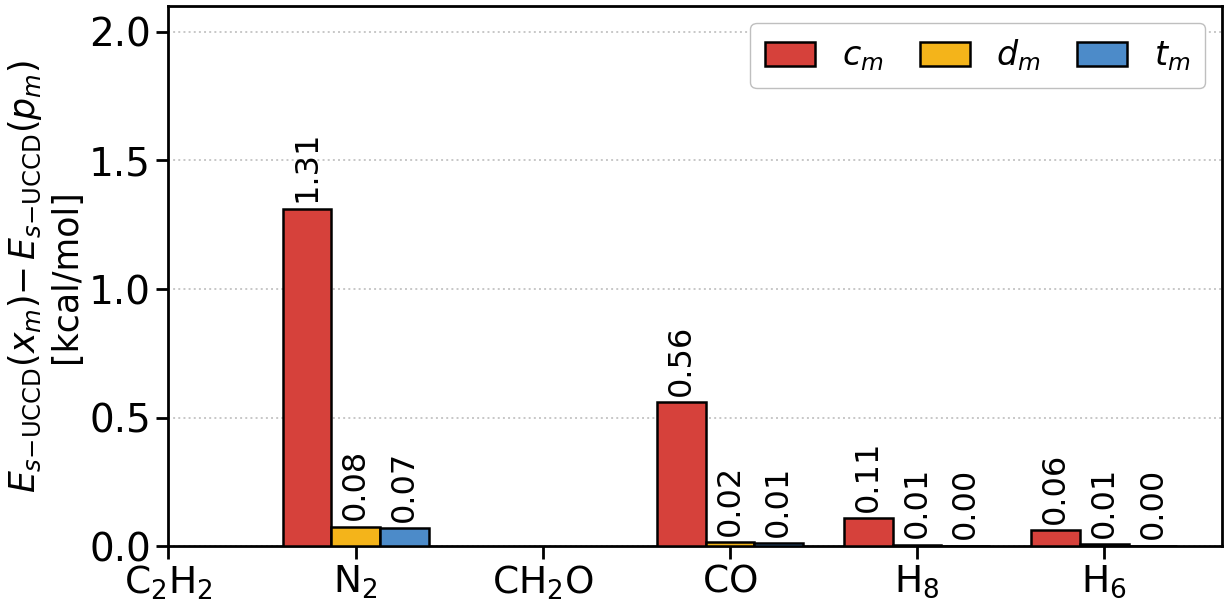

In [13]:
# ===================================================================
# FIGURE 5 — residual correlation energy.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 24, 23

fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 2.10        # raise y_top if numerals hit the frame
annot_pad       = 0.012          # gap above the bar, as a fraction of the axes
colour_c, colour_d, colour_t = "#d6413b", "#f4b41a", "#4c8bc9"

order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = FRAMES["fig5_residual"]
c = df[df.source == "c_m"].set_index("molecule")
d = df[df.source == "d_m"].set_index("molecule")
t = df[df.source == "t_m"].set_index("molecule")

res_c = [c.loc[m, "residual_kcalmol"] for m in order]
res_d = [d.loc[m, "residual_kcalmol"] for m in order]
res_t = [t.loc[m, "residual_kcalmol"] for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, res_c, bar_w, color=colour_c, edgecolor="black",
       linewidth=1.8, zorder=3, label=r"$c_m$")
ax.bar(x, res_d, bar_w, color=colour_d, edgecolor="black",
       linewidth=1.8, zorder=3, label=r"$d_m$")
ax.bar(x + bar_w, res_t, bar_w, color=colour_t, edgecolor="black",
       linewidth=1.8, zorder=3, label=r"$t_m$")

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, res_c):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, res_d):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, res_t):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel(r"$E_{s\mathrm{-UCCD}}(x_m)$" 
              r"$-\,E_{s\mathrm{-UCCD}}(p_m)$" "\n[kcal/mol]",
              fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"{TAG}_fig5_residual_correlation.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/fig5_residual_correlation.pdf")
plt.show()

### Figure 6 — quadruple correlation energy

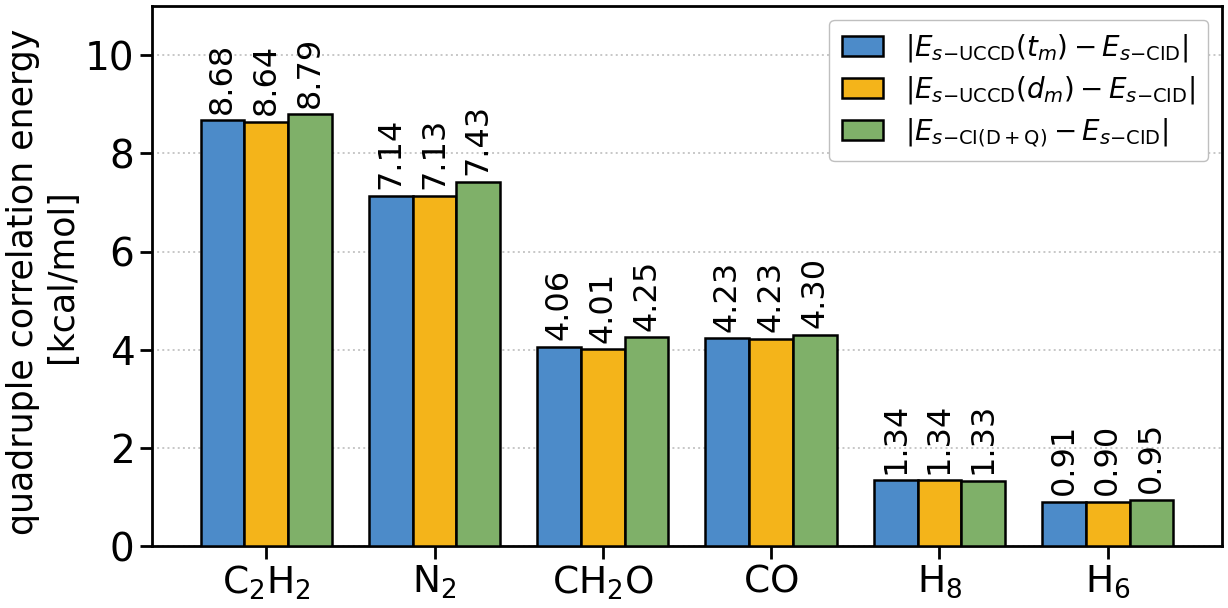

In [14]:
# ===================================================================
# FIGURE 6 — quadruple correlation energy.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_annot = 30, 32, 32, 26
fs_legend       = 23             # smaller: these entries are long expressions
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 11.0        # raise y_top if numerals hit the frame
annot_pad       = 0.012
colour_t, colour_d, colour_Q = "#4c8bc9", "#f4b41a", "#7fb069"
order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 20, 23

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

# ---- DATA ---------------------------------------------------------
df = FRAMES["fig6_quadruples"]
name_t = "|E_sUCCD(t_m) - E_sCID|"
name_d = "|E_sUCCD(d_m) - E_sCID|"
name_Q = "|E_sCI(D+Q) - E_sCID|"

t = df[df.quantity == name_t].set_index("molecule")
d = df[df.quantity == name_d].set_index("molecule")
Q = df[df.quantity == name_Q].set_index("molecule")

val_t = [t.loc[m, "energy_kcalmol"] for m in order]
val_d = [d.loc[m, "energy_kcalmol"] for m in order]
val_Q = [Q.loc[m, "energy_kcalmol"] for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, val_t, bar_w, color=colour_t, edgecolor="black",
       linewidth=1.8, zorder=3,
       label=r"$|E_{s\mathrm{-UCCD}}(t_m)-E_{s\mathrm{-CID}}|$")
ax.bar(x,         val_d, bar_w, color=colour_d, edgecolor="black",
       linewidth=1.8, zorder=3,
       label=r"$|E_{s\mathrm{-UCCD}}(d_m)-E_{s\mathrm{-CID}}|$")
ax.bar(x + bar_w, val_Q, bar_w, color=colour_Q, edgecolor="black",
       linewidth=1.8, zorder=3,
       label=r"$|E_{s\mathrm{-CI(D+Q)}}-E_{s\mathrm{-CID}}|$")

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, val_t):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, val_d):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, val_Q):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel("quadruple correlation energy \n[kcal/mol]", fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"{TAG}_fig6_quadruple_correlation_energy.png"),
            dpi=dpi)
#fig.savefig("figures_from_notebook/fig6_quadruple_correlation_energy.pdf")
plt.show()

### Figure A1 — Enhanced CISD

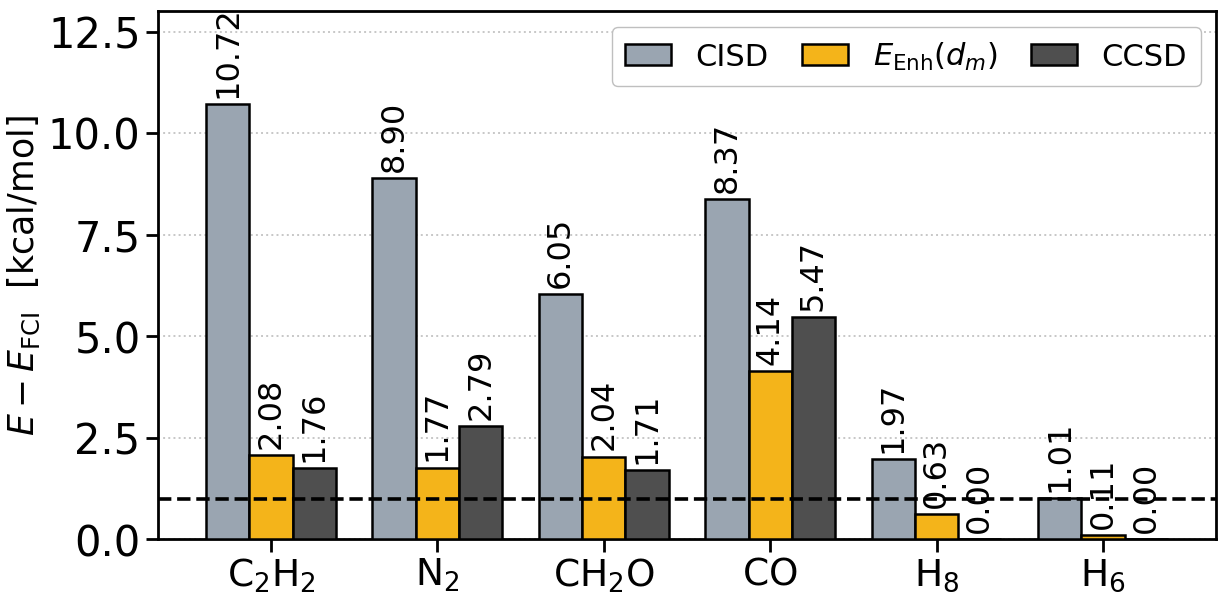

In [15]:
# ===================================================================
# FIGURE A1 — Enhanced CISD.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 0, 13.0        # raise y_top if numerals hit the frame
annot_pad       = 0.012
chemical_accuracy = 1.0
colour_CISD, colour_Enh, colour_CCSD = "#9aa5b1", "#f4b41a", "#4f4f4f"
order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 22, 23

# ---- DATA ---------------------------------------------------------
df   = FRAMES["figA1_enhanced_cisd"]
cisd = df[df.method == "CISD"].set_index("molecule")
enh  = df[df.method == "Enh(d_m)"].set_index("molecule")
ccsd = df[df.method == "CCSD"].set_index("molecule")

val_CISD = [cisd.loc[m, "dev_from_FCI_kcalmol"] for m in order]
val_Enh  = [enh.loc[m,  "dev_from_FCI_kcalmol"] for m in order]
val_CCSD = [ccsd.loc[m, "dev_from_FCI_kcalmol"] for m in order]

x   = np.arange(len(order))
pad = annot_pad * (y_top - y_bottom)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, val_CISD, bar_w, color=colour_CISD, edgecolor="black",
       linewidth=1.8, label="CISD", zorder=3)
ax.bar(x,         val_Enh,  bar_w, color=colour_Enh,  edgecolor="black",
       linewidth=1.8, label=r"$E_{\mathrm{Enh}}(d_m)$", zorder=3)
ax.bar(x + bar_w, val_CCSD, bar_w, color=colour_CCSD, edgecolor="black",
       linewidth=1.8, label="CCSD", zorder=3)

# ---- PLOT: numbers above the bars ---------------------------------
for xi, v in zip(x - bar_w, val_CISD):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, val_Enh):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, val_CCSD):
    ax.text(xi, v + pad, f"{v:.2f}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

# chemical accuracy, drawn on top of the bars
ax.axhline(chemical_accuracy, color="black", linestyle="--", linewidth=2.6,
           zorder=4)

ax.set_ylabel(r"$E-E_{\mathrm{FCI}}$  [kcal/mol]", fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"{TAG}_figA1_enhanced_cisd.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/figA1_enhanced_cisd.pdf")
plt.show()

### Figure A2 — SQD deviation

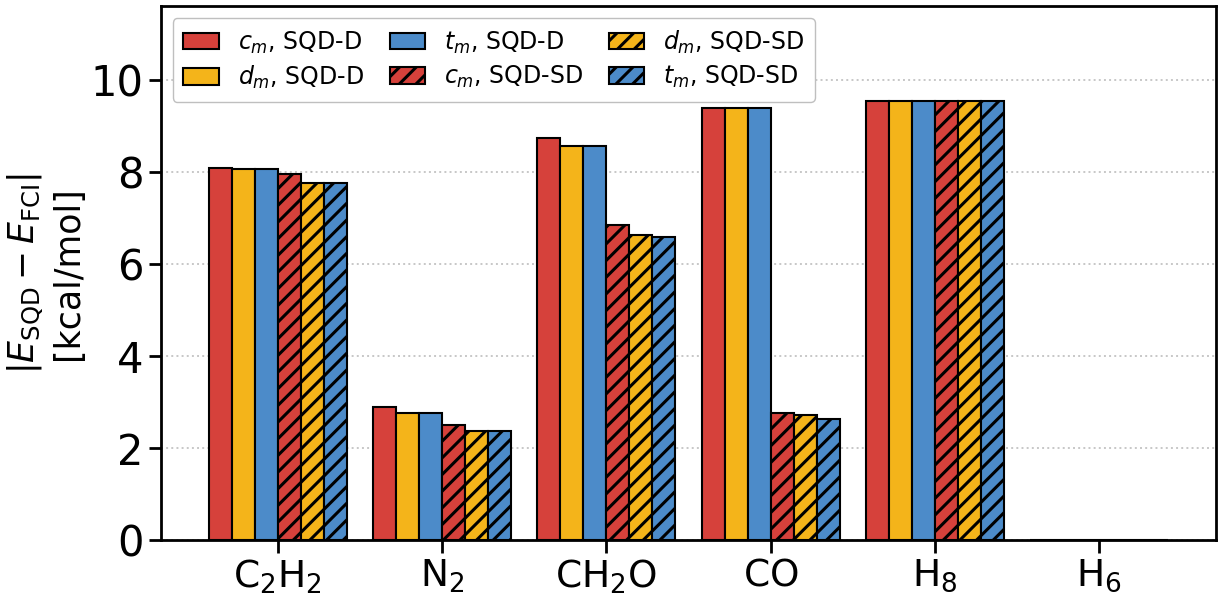

In [16]:
# ===================================================================
# FIGURE A2 — SQD deviation at 1e8 measurements.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label = 30, 32, 32
fs_legend       = 24             # smaller: six entries have to fit
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.14
y_bottom, y_top = 0, 11.6
colour_c, colour_d, colour_t = "#d6413b", "#f4b41a", "#4c8bc9"
order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})

fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 17, 23
# ---- DATA ---------------------------------------------------------
df  = FRAMES["figA2_sqd"]
col = "abs_dev_from_FCI_kcalmol"

cD  = df[(df.parameters == "c") & (df.subspace == "SQD-D")].set_index("molecule")
dD  = df[(df.parameters == "d") & (df.subspace == "SQD-D")].set_index("molecule")
tD  = df[(df.parameters == "t") & (df.subspace == "SQD-D")].set_index("molecule")
cSD = df[(df.parameters == "c") & (df.subspace == "SQD-SD")].set_index("molecule")
dSD = df[(df.parameters == "d") & (df.subspace == "SQD-SD")].set_index("molecule")
tSD = df[(df.parameters == "t") & (df.subspace == "SQD-SD")].set_index("molecule")

val_cD  = [cD.loc[m, col]  for m in order]
val_dD  = [dD.loc[m, col]  for m in order]
val_tD  = [tD.loc[m, col]  for m in order]
val_cSD = [cSD.loc[m, col] for m in order]
val_dSD = [dSD.loc[m, col] for m in order]
val_tSD = [tSD.loc[m, col] for m in order]

x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: six series, plain = SQD-D, hatched = SQD-SD ------------
ax.bar(x - 2.5 * bar_w, val_cD,  bar_w, color=colour_c, edgecolor="black",
       linewidth=1.5, zorder=3, label=r"$c_m$, SQD-D")
ax.bar(x - 1.5 * bar_w, val_dD,  bar_w, color=colour_d, edgecolor="black",
       linewidth=1.5, zorder=3, label=r"$d_m$, SQD-D")
ax.bar(x - 0.5 * bar_w, val_tD,  bar_w, color=colour_t, edgecolor="black",
       linewidth=1.5, zorder=3, label=r"$t_m$, SQD-D")
ax.bar(x + 0.5 * bar_w, val_cSD, bar_w, color=colour_c, edgecolor="black",
       linewidth=1.5, zorder=3, hatch="//", label=r"$c_m$, SQD-SD")
ax.bar(x + 1.5 * bar_w, val_dSD, bar_w, color=colour_d, edgecolor="black",
       linewidth=1.5, zorder=3, hatch="//", label=r"$d_m$, SQD-SD")
ax.bar(x + 2.5 * bar_w, val_tSD, bar_w, color=colour_t, edgecolor="black",
       linewidth=1.5, zorder=3, hatch="//", label=r"$t_m$, SQD-SD")

ax.set_ylabel(r"$|E_{\mathrm{SQD}}-E_{\mathrm{FCI}}|$" "\n[kcal/mol]",
              fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper left", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"{TAG}_figA2_sqd_deviation.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/figA2_sqd_deviation.pdf")
plt.show()

### Figure A3 — determinant counts

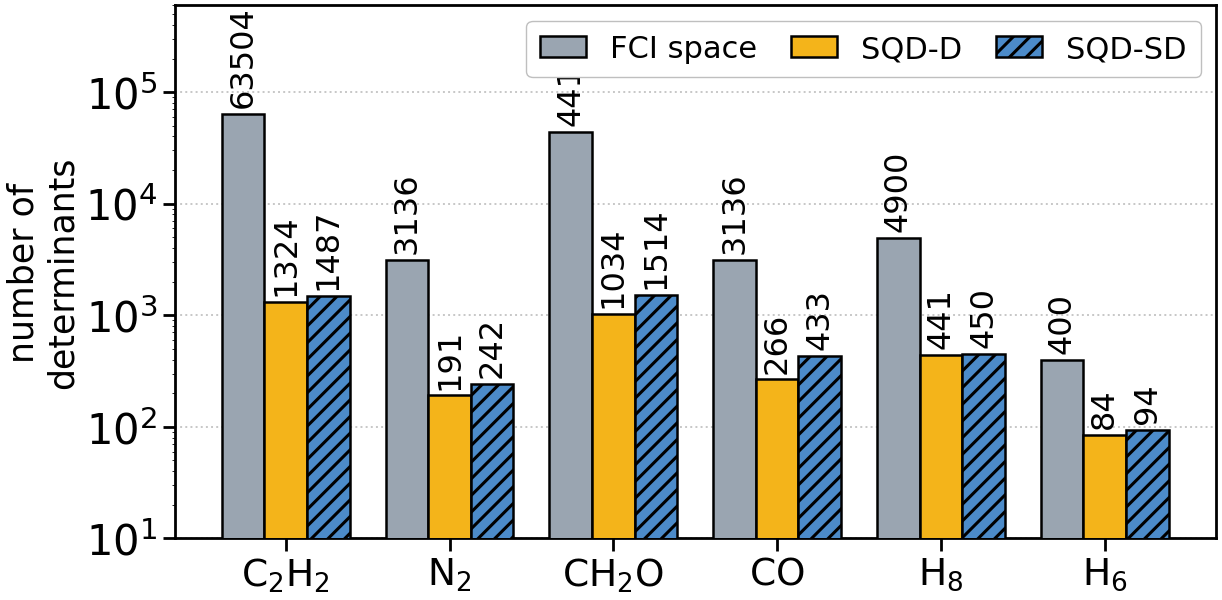

In [17]:
# ===================================================================
# FIGURE A3 — determinant counts.  Run this cell alone.
# ===================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ---- SETTINGS -----------------------------------------------------
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 30, 32, 32, 27, 26
fig_w, fig_h, dpi = 13.0, 6.8, 600
bar_w           = 0.26
y_bottom, y_top = 10, 6.0e5      # raise y_top if numerals hit the frame
colour_FCI, colour_D, colour_SD = "#9aa5b1", "#f4b41a", "#4c8bc9"
order  = [m for m in ["C2H2","N2","CH2O","CO","H8","H6"] if m in ORDER]
labels = [PRETTY[m] for m in order]

# ---- STYLE --------------------------------------------------------
plt.rcParams.update({
    "font.size": fs_tick,
    "xtick.labelsize": fs_tick, "ytick.labelsize": fs_tick,
    "axes.linewidth": 2.0,
    "xtick.major.size": 9, "ytick.major.size": 9,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0,
    "legend.framealpha": 1.0, "legend.edgecolor": "0.75",
    "legend.borderpad": 0.45, "legend.handlelength": 1.5,
    "legend.columnspacing": 1.1, "legend.labelspacing": 0.35,
    "grid.linestyle": ":", "grid.linewidth": 1.4, "grid.color": "0.78",
    "hatch.linewidth": 2.2,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.06,
})
fs_tick, fs_mol, fs_label, fs_legend, fs_annot = 28, 27, 25, 22, 23
# ---- DATA ---------------------------------------------------------
df  = FRAMES["figA3_determinants"]
fci = df[df.series == "FCI space"].set_index("molecule")
sD  = df[df.series == "SQD-D"].set_index("molecule")
sSD = df[df.series == "SQD-SD"].set_index("molecule")

val_FCI = [fci.loc[m, "count"] for m in order]
val_D   = [sD.loc[m,  "count"] for m in order]
val_SD  = [sSD.loc[m, "count"] for m in order]

x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_yscale("log")
ax.set_ylim(y_bottom, y_top)

# ---- PLOT: three series -------------------------------------------
ax.bar(x - bar_w, val_FCI, bar_w, color=colour_FCI, edgecolor="black",
       linewidth=1.8, label="FCI space", zorder=3)
ax.bar(x,         val_D,   bar_w, color=colour_D,   edgecolor="black",
       linewidth=1.8, label="SQD-D", zorder=3)
ax.bar(x + bar_w, val_SD,  bar_w, color=colour_SD,  edgecolor="black",
       linewidth=1.8, label="SQD-SD", hatch="//", zorder=3)

# ---- PLOT: numbers above the bars (log axis -> multiply, not add) --
for xi, v in zip(x - bar_w, val_FCI):
    ax.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x, val_D):
    ax.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)
for xi, v in zip(x + bar_w, val_SD):
    ax.text(xi, v * 1.144, f"{v:d}", rotation=90, ha="center", va="bottom",
            fontsize=fs_annot, clip_on=False)

ax.set_ylabel("number of\ndeterminants", fontsize=fs_label)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fs_mol)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="upper right", ncol=3, fontsize=fs_legend)

# ---- SAVE ---------------------------------------------------------
fig.tight_layout()
#os.makedirs("figures_from_notebook", exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"{TAG}_figA3_determinant_counts.png"), dpi=dpi)
#fig.savefig("figures_from_notebook/figA3_determinant_counts.pdf")
plt.show()

## Noise condition (SI Table 8)

In [18]:
noise = pd.DataFrame([dict(molecule=m, **RES[m]['noise']) for m in ORDER
                      if RES[m].get('noise')])
if len(noise):
    noise.to_csv(os.path.join(VALDIR, '%s_noise.csv' % TAG), index=False)
    print(noise.to_string(index=False))

molecule  dets_95  populated     D        w_min   D_wmin  p_required  N_CX
    C2H2     1074       3297 63504 1.909638e-08 0.001213    0.998789     0
      N2       48        220  3136 7.770944e-05 0.243697    0.804054    94
    CH2O      295       2919 44100 7.465431e-07 0.032923    0.968127    14
      CO       52        302  3136 4.301408e-05 0.134892    0.881141    54
      H8       63        442  4900 2.528756e-04 1.239090    0.446610   350
      H6       39         84   400 2.802990e-05 0.011212    0.988912     4
